# Customer Churn & A/B Test Analysis

## Business Problem

Customer churn is an important business problem because losing customers can reduce recurring revenue and increase the need to acquire new customers.

The goal of this project is to identify customer characteristics associated with churn and evaluate a simulated retention email campaign using a randomized A/B test.

The analysis focuses on two questions:

1. Which customer characteristics are associated with churn?
2. Does the simulated retention email show evidence of reducing 30-day churn?

The final analysis combines exploratory data analysis, statistical hypothesis testing, and A/B testing to support a data-driven business recommendation.


# Executive Summary

The analysis found several customer characteristics associated with churn. Churn was higher among customers with shorter tenure, higher monthly charges, month-to-month contracts, electronic check payment methods, fiber optic internet service, senior-citizen status, and no online security service.

Statistical testing also found strong evidence of an association between contract type and churn, as well as a significant difference in average tenure and monthly charges between churned and non-churned customers. These results describe associations in the historical dataset and do not prove causation.

A simulated randomized A/B test was used to evaluate a retention email campaign. The control group had an 11.79% 30-day churn rate, while the treatment group had a 10.96% churn rate. This represents an absolute reduction of 0.83 percentage points and a relative churn reduction of 7.02%.

However, the result was not statistically significant at the 5% level (p = 0.0533), and the 95% confidence interval included zero. Therefore, the simulation does not provide sufficient statistical evidence to conclude that the retention email changes 30-day churn.

Because the experiment was simulated rather than conducted with real customers, the observed effect should be treated as an experimental result rather than confirmed campaign performance.


### Imports and Configuration

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

### Dataset Loading

In [2]:
df = pd.read_csv('customer_churn_ab_test/data/WA_Fn-UseC_-Telco-Customer-Churn.csv')

### Data Quality Checks

In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.tail()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


In [5]:
df.shape

(7043, 21)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [7]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [8]:
df_clean = df.copy()

In [9]:
df_clean.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [10]:
duplicate_rows = df_clean.duplicated().sum()
duplicate_rows

np.int64(0)

In [11]:
missing_values = df_clean.isnull().sum()
missing_values

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [12]:
missing_values[missing_values > 0]

Series([], dtype: int64)

In [13]:
df_clean.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [14]:
df_clean['Churn'].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [15]:
df_clean['Churn'].value_counts(normalize=True).mul(100).round(2)

Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64

### Data Cleaning

In [16]:
blank_total_charges = df_clean["TotalCharges"].str.strip().eq("").sum()

In [17]:
blank_total_charges

np.int64(11)

In [18]:
df_clean["TotalCharges"] = df_clean["TotalCharges"].replace(r"^\s*$", np.nan, regex=True)

In [19]:
df_clean["TotalCharges"] = pd.to_numeric(df_clean["TotalCharges"], errors="coerce")

In [20]:
df_clean["TotalCharges"].dtype

dtype('float64')

In [21]:
df_clean["TotalCharges"].isnull().sum()

np.int64(11)

In [22]:
df_clean.loc[df_clean["TotalCharges"].isnull(), ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


In [23]:
df_clean.loc[df_clean["TotalCharges"].isnull(), "tenure"].value_counts()

tenure
0    11
Name: count, dtype: int64

In [24]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [25]:
df_clean.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7032.000000
mean,0.162147,32.371149,64.761692,2283.300441
std,0.368612,24.559481,30.090047,2266.771362
min,0.000000,0.000000,18.250000,18.800000
25%,0.000000,9.000000,35.500000,401.450000
50%,0.000000,29.000000,70.350000,1397.475000
75%,0.000000,55.000000,89.850000,3794.737500
max,1.000000,72.000000,118.750000,8684.800000


In [26]:
df_clean.isnull().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

### Exploratory Data Analysis

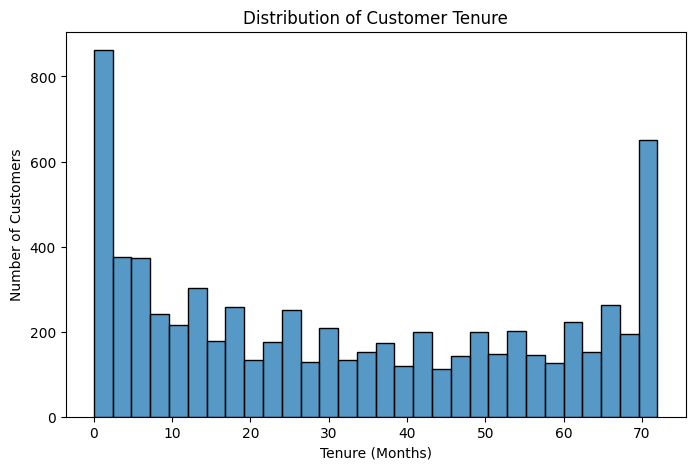

In [27]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df_clean,x="tenure",bins=30)

plt.title("Distribution of Customer Tenure")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")
plt.show()

Customer tenure is distributed across the full range of approximately 0 to 72 months, but the distribution is not uniform. There is a particularly large concentration of customers at very low tenure, while another substantial concentration appears around 70–72 months. The middle tenure ranges generally contain fewer customers. This suggests that the customer base contains both many newer customers and many long-tenured customers.

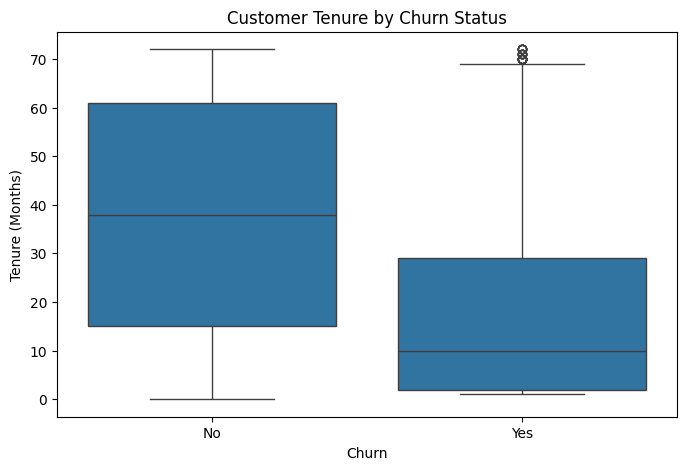

In [28]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df_clean,x="Churn",y="tenure")

plt.title("Customer Tenure by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")
plt.show()

In [29]:
tenure_summary = df_clean.groupby("Churn")["tenure"].agg(["count", "mean", "median", "min", "max"]).round(2)

tenure_summary

,count,mean,median,min,max
Churn,,,,,
No,5174,37.57,38.0,0,72
Yes,1869,17.98,10.0,1,72


Customers who churned have a much lower average and median tenure than customers who did not churn. The average tenure is 17.98 months for churned customers compared with 37.57 months for non-churned customers. The median is 10 months for churned customers and 38 months for non-churned customers. This shows that customers with shorter tenure are more common among the churned group.

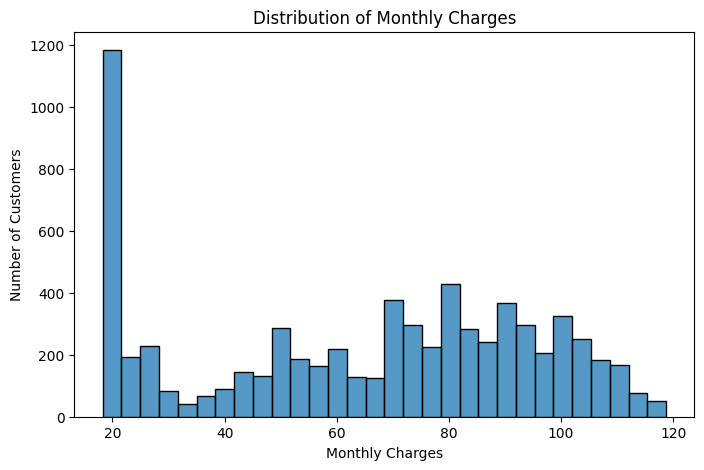

In [30]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df_clean,x="MonthlyCharges",bins=30)

plt.title("Distribution of Monthly Charges")
plt.xlabel("Monthly Charges")
plt.ylabel("Number of Customers")
plt.show()

Monthly charges range from around 18 to 120. There is a large concentration of customers at the lower end, especially around 20, while many other customers have charges between about 60 and 110. The distribution is spread across a wide range of monthly charges.

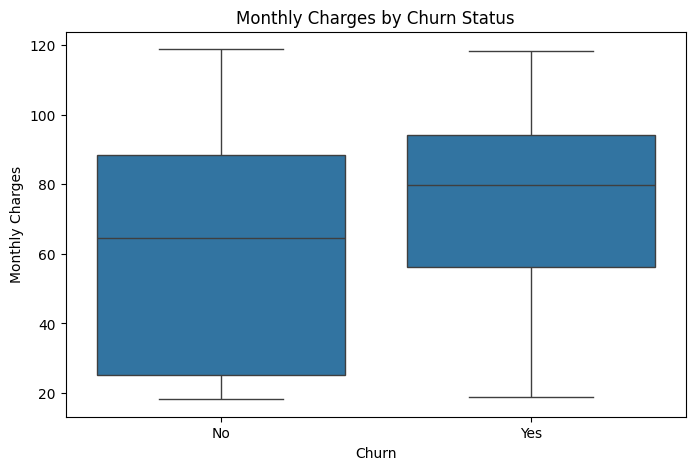

In [31]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df_clean,x="Churn",y="MonthlyCharges")

plt.title("Monthly Charges by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")
plt.show()

Customers who churned generally have higher monthly charges than customers who did not churn. The median monthly charge is around 80 for churned customers compared with around 65 for non-churned customers.

In [32]:
monthly_charges_summary = df_clean.groupby("Churn")["MonthlyCharges"].agg(["count", "mean", "median", "min", "max"]).round(2)

monthly_charges_summary

,count,mean,median,min,max
Churn,,,,,
No,5174,61.27,64.43,18.25,118.75
Yes,1869,74.44,79.65,18.85,118.35


Customers who churned have higher monthly charges than customers who did not churn. The average monthly charge is 74.44 for churned customers compared with 61.27 for non-churned customers. The median is also higher for churned customers (79.65 vs 64.43).

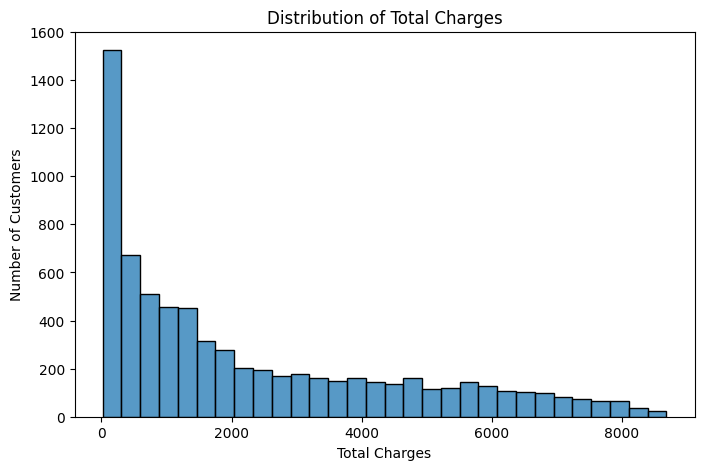

In [33]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df_clean,x="TotalCharges",bins=30)

plt.title("Distribution of Total Charges")
plt.xlabel("Total Charges")
plt.ylabel("Number of Customers")
plt.show()

TotalCharges are highly concentrated at the lower end and gradually decrease as the total charge increases. Most customers have relatively low total charges, while fewer customers have very high total charges.

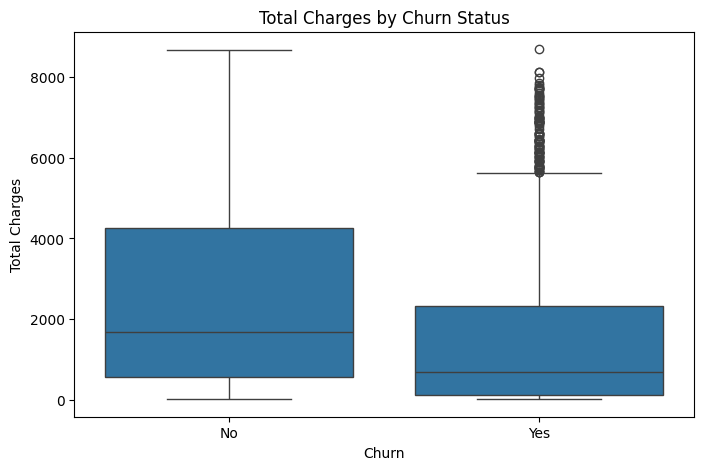

In [34]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df_clean,x="Churn",y="TotalCharges")

plt.title("Total Charges by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Total Charges")
plt.show()

In [35]:
total_charges_summary = df_clean.groupby("Churn")["TotalCharges"].agg(["count", "mean", "median", "min", "max"]).round(2)

total_charges_summary

,count,mean,median,min,max
Churn,,,,,
No,5163,2555.34,1683.60,18.80,8672.45
Yes,1869,1531.80,703.55,18.85,8684.80


Customers who did not churn have higher TotalCharges than customers who churned. The average TotalCharges is 2555.34 for non-churned customers compared with 1531.80 for churned customers. The median is also higher for non-churned customers (1683.60 vs 703.55). This is mainly related to the fact that customers who stay longer have more time to accumulate charges.

Note : No group has 5163 observations instead of 5174 because the 11 missing TotalCharges values are excluded from these calculations.

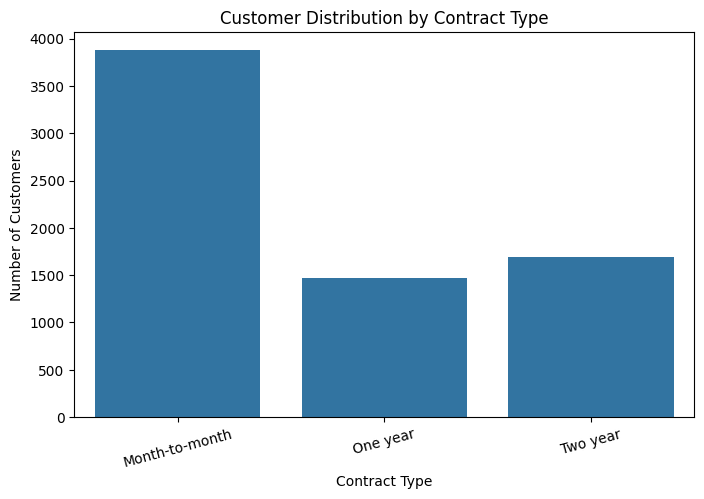

In [36]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df_clean,x="Contract")

plt.title("Customer Distribution by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=15)
plt.show()

Most customers have a month-to-month contract. One-year and two-year contracts have fewer customers, with the one-year group being the smallest.

In [37]:
contract_churn_rate = (df_clean.groupby("Contract")["Churn"].apply(lambda x: (x == "Yes").mean() * 100).round(2))

contract_churn_rate

Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn, dtype: float64

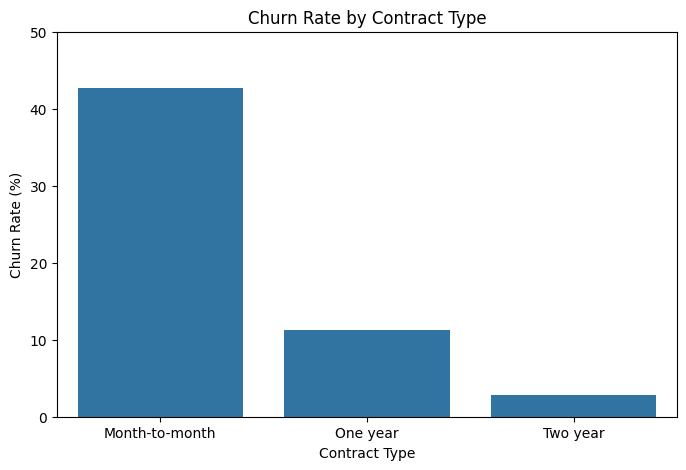

In [38]:
plt.figure(figsize=(8, 5))

sns.barplot(x=contract_churn_rate.index, y=contract_churn_rate.values)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 50)
plt.show()

Churn is much higher among month-to-month customers. The churn rate is 42.71% for month-to-month customers, compared with 11.27% for one-year customers and 2.83% for two-year customers. This shows a strong difference in churn rates across contract types.

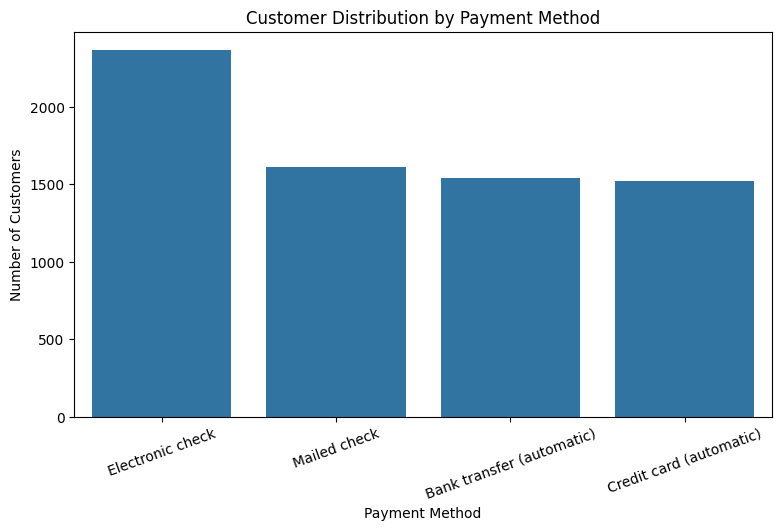

In [39]:
plt.figure(figsize=(9, 5))

sns.countplot(data=df_clean,x="PaymentMethod")

plt.title("Customer Distribution by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Customers")
plt.xticks(rotation=20)
plt.show()

Electronic check is the most common payment method. The other three payment methods have similar numbers of customers, with mailed check slightly higher than bank transfer and credit card.

In [40]:
payment_churn_rate = (df_clean.groupby("PaymentMethod")["Churn"].apply(lambda x: (x == "Yes").mean() * 100).round(2))

payment_churn_rate

PaymentMethod
Bank transfer (automatic)    16.71
Credit card (automatic)      15.24
Electronic check             45.29
Mailed check                 19.11
Name: Churn, dtype: float64

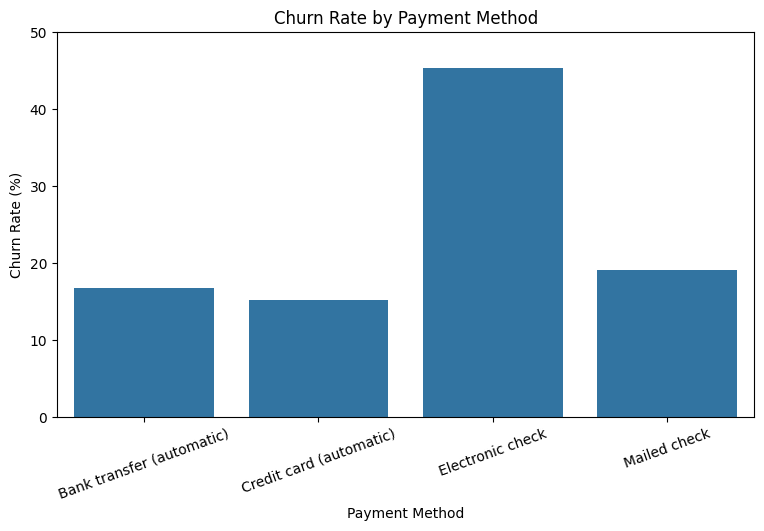

In [41]:
plt.figure(figsize=(9, 5))

sns.barplot(x=payment_churn_rate.index,y=payment_churn_rate.values)

plt.title("Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=20)
plt.ylim(0, 50)
plt.show()

Customers using electronic check have the highest churn rate at 45.29%. The other payment methods have much lower churn rates, ranging from 15.24% to 19.11%.

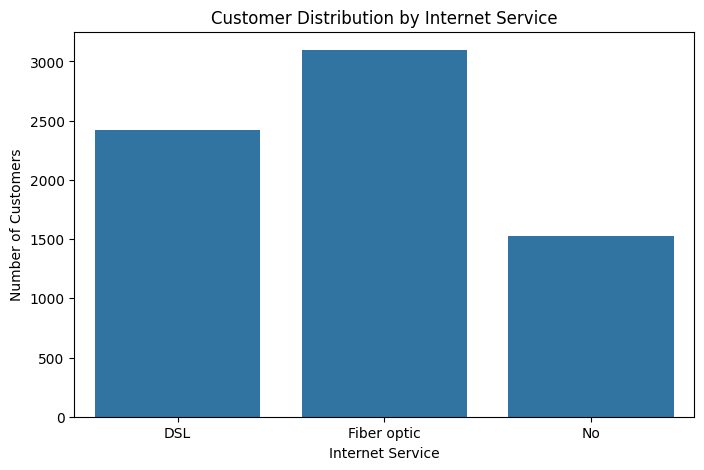

In [42]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df_clean,x="InternetService")

plt.title("Customer Distribution by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Number of Customers")
plt.show()

Fiber optic is the most common internet service among the customers, followed by DSL. Customers without internet service form the smallest group.

In [43]:
internet_churn_rate = (df_clean.groupby("InternetService")["Churn"].apply(lambda x: (x == "Yes").mean() * 100).round(2))

internet_churn_rate

InternetService
DSL            18.96
Fiber optic    41.89
No              7.40
Name: Churn, dtype: float64

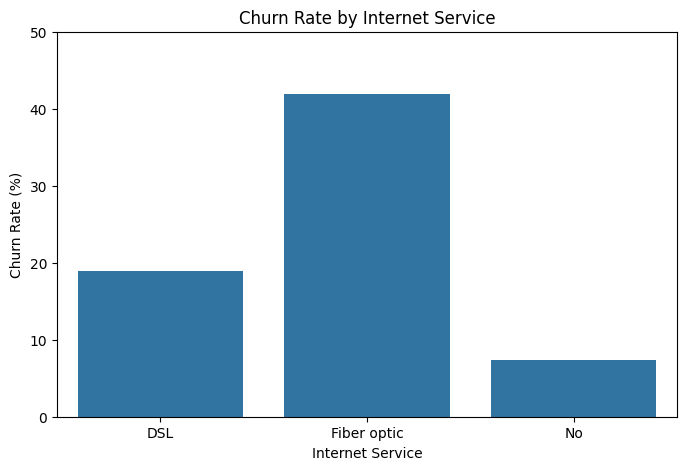

In [44]:
plt.figure(figsize=(8, 5))

sns.barplot(x=internet_churn_rate.index,y=internet_churn_rate.values)

plt.title("Churn Rate by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 50)
plt.show()

Fiber optic customers have the highest churn rate at 41.89%, followed by DSL at 18.96%. Customers without internet service have the lowest churn rate at 7.40%.

In [45]:
senior_churn_rate = (df_clean.groupby("SeniorCitizen")["Churn"].apply(lambda x: (x == "Yes").mean() * 100).round(2))

senior_churn_rate

SeniorCitizen
0    23.61
1    41.68
Name: Churn, dtype: float64

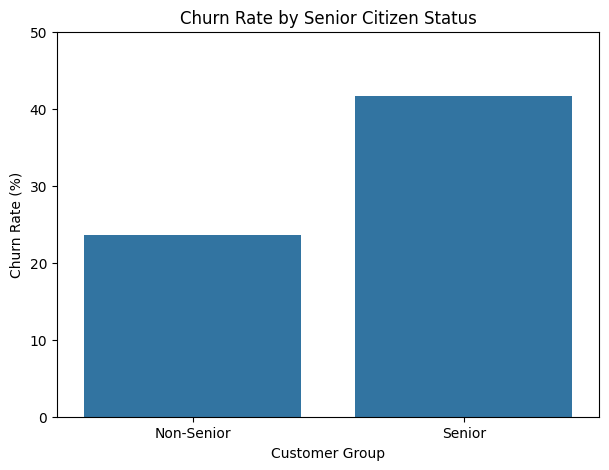

In [46]:
senior_churn_rate.index = ["Non-Senior", "Senior"]

plt.figure(figsize=(7, 5))

sns.barplot(x=senior_churn_rate.index,y=senior_churn_rate.values)

plt.title("Churn Rate by Senior Citizen Status")
plt.xlabel("Customer Group")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 50)
plt.show()

Senior citizens have a higher churn rate than non-senior customers. The churn rate is 41.68% for senior citizens compared with 23.61% for non-senior customers.

In [47]:
online_security_churn_rate = (df_clean.groupby("OnlineSecurity")["Churn"].apply(lambda x: (x == "Yes").mean() * 100).round(2))

online_security_churn_rate

OnlineSecurity
No                     41.77
No internet service     7.40
Yes                    14.61
Name: Churn, dtype: float64

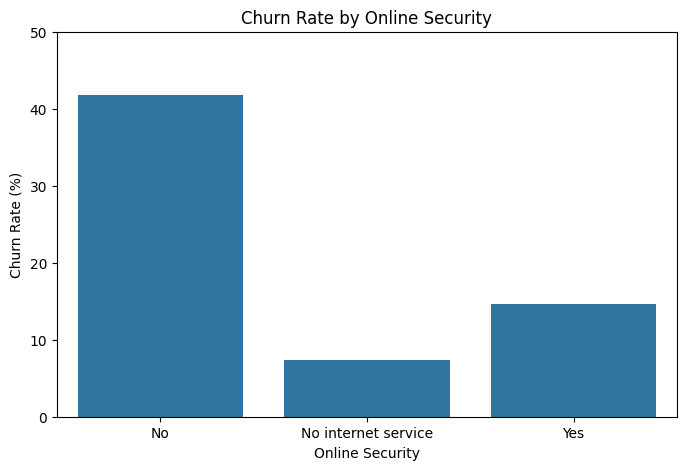

In [48]:
plt.figure(figsize=(8, 5))

sns.barplot(x=online_security_churn_rate.index,y=online_security_churn_rate.values)

plt.title("Churn Rate by Online Security")
plt.xlabel("Online Security")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 50)
plt.show()

Customers without OnlineSecurity have a higher churn rate (41.77%) than customers with OnlineSecurity (14.61%). Customers with no internet service have the lowest churn rate at 7.40%.

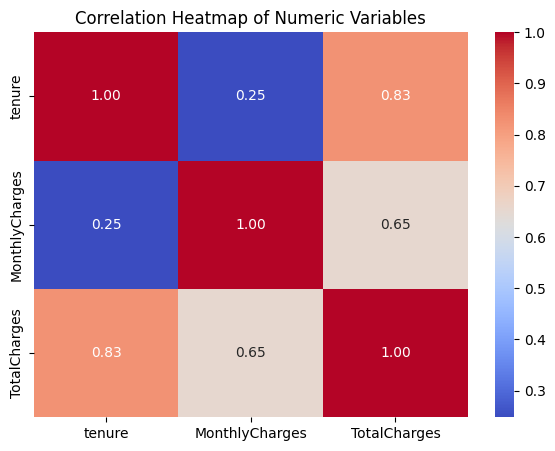

In [49]:
numeric_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

plt.figure(figsize=(7, 5))

sns.heatmap(df_clean[numeric_cols].corr(),annot=True,cmap="coolwarm",fmt=".2f")

plt.title("Correlation Heatmap of Numeric Variables")
plt.show()

Tenure and TotalCharges have a strong positive correlation (0.83), meaning customers with longer tenure generally have higher total charges. MonthlyCharges and TotalCharges have a moderate positive correlation (0.65). Tenure and MonthlyCharges have a weak positive correlation (0.25).

In [50]:
churn_percentage = (df_clean["Churn"].value_counts(normalize=True).mul(100).round(2))

print(churn_percentage)

Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


The dataset contains 73.46% customers who did not churn and 26.54% customers who churned. This shows that the Churn variable is imbalanced, with non-churned customers making up the larger group.

In [51]:
print(df_clean.isnull().sum())

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64


In [52]:
print(df_clean[["tenure", "MonthlyCharges", "TotalCharges"]].describe())

            tenure  MonthlyCharges  TotalCharges
count  7043.000000     7043.000000   7032.000000
mean     32.371149       64.761692   2283.300441
std      24.559481       30.090047   2266.771362
min       0.000000       18.250000     18.800000
25%       9.000000       35.500000    401.450000
50%      29.000000       70.350000   1397.475000
75%      55.000000       89.850000   3794.737500
max      72.000000      118.750000   8684.800000


### Feature Engineering

In [53]:
df_clean["TenureGroup"] = pd.cut(df_clean["tenure"], bins=[-1, 12, 24, 48, 72], labels=["0-12", "13-24", "25-48", "49-72"])

print(df_clean["TenureGroup"].value_counts().sort_index())

TenureGroup
0-12     2186
13-24    1024
25-48    1594
49-72    2239
Name: count, dtype: int64


The customers are distributed across all four tenure groups. The 49–72 month group has the highest number of customers (2,239), followed by the 0–12 month group (2,186). The 13–24 month group has the fewest customers (1,024).

In [54]:
print(df_clean.dtypes)

customerID            object
gender                object
SeniorCitizen          int64
Partner               object
Dependents            object
tenure                 int64
PhoneService          object
MultipleLines         object
InternetService       object
OnlineSecurity        object
OnlineBackup          object
DeviceProtection      object
TechSupport           object
StreamingTV           object
StreamingMovies       object
Contract              object
PaperlessBilling      object
PaymentMethod         object
MonthlyCharges       float64
TotalCharges         float64
Churn                 object
TenureGroup         category
dtype: object


### Hypothesis Testing

#### Test 1 - Contract vs Churn

In [55]:
from scipy.stats import chi2_contingency

# Create contingency table
contract_churn_table = pd.crosstab(df_clean["Contract"],df_clean["Churn"])

print("Contingency Table:")
print(contract_churn_table)

# Perform chi-square test
chi2, p_value, dof, expected = chi2_contingency(contract_churn_table)

print("\nChi-square statistic:", chi2)
print("Degrees of freedom:", dof)
print("P-value:", p_value)

Contingency Table:
Churn             No   Yes
Contract                  
Month-to-month  2220  1655
One year        1307   166
Two year        1647    48

Chi-square statistic: 1184.5965720837926
Degrees of freedom: 2
P-value: 5.863038300673391e-258


The chi-square test found a statistically significant association between contract type and customer churn (χ² = 1184.60, df = 2, p < 0.05). Therefore, we reject the null hypothesis that contract type and churn are independent. Customers with different contract types have significantly different churn rates. However, this result shows an association between contract type and churn and does not prove that contract type causes customers to churn.

#### Test 2 - Tenure vs Churn

In [56]:
from scipy.stats import ttest_ind

# Separate tenure values by churn status
tenure_no = df_clean.loc[df_clean["Churn"] == "No", "tenure"]
tenure_yes = df_clean.loc[df_clean["Churn"] == "Yes", "tenure"]

# Welch's independent two-sample t-test
t_stat, p_value = ttest_ind(tenure_no,tenure_yes,equal_var=False)

print("Mean tenure - No churn:", tenure_no.mean())
print("Mean tenure - Churn:", tenure_yes.mean())
print("Mean difference:", tenure_no.mean() - tenure_yes.mean())
print("T-statistic:", t_stat)
print("P-value:", p_value)

Mean tenure - No churn: 37.56996521066873
Mean tenure - Churn: 17.979133226324237
Mean difference: 19.59083198434449
T-statistic: 34.823818696312976
P-value: 1.1954945472607151e-232


The Welch's independent two-sample t-test found a statistically significant difference in mean tenure between customers who churned and those who did not (t = 34.82, p < 0.05). Customers who did not churn had a higher average tenure of 37.57 months, compared with 17.98 months for customers who churned. The mean difference was approximately 19.59 months. Therefore, we reject the null hypothesis that the two groups have equal mean tenure.

#### Test 3 - Monthly Charges vs Churn

In [57]:
from scipy.stats import ttest_ind

# Separate monthly charges by churn status
charges_no = df_clean.loc[df_clean["Churn"] == "No", "MonthlyCharges"]
charges_yes = df_clean.loc[df_clean["Churn"] == "Yes", "MonthlyCharges"]

# Welch's independent two-sample t-test
t_stat, p_value = ttest_ind(charges_no,charges_yes,equal_var=False)

print("Mean MonthlyCharges - No churn:", charges_no.mean())
print("Mean MonthlyCharges - Churn:", charges_yes.mean())
print("Mean difference:", charges_yes.mean() - charges_no.mean())
print("T-statistic:", t_stat)
print("P-value:", p_value)

Mean MonthlyCharges - No churn: 61.26512369540008
Mean MonthlyCharges - Churn: 74.44133226324237
Mean difference: 13.176208567842295
T-statistic: -18.407526676414673
P-value: 8.59244933154705e-73


The Welch's independent two-sample t-test found a statistically significant difference in mean monthly charges between customers who churned and those who did not (t = -18.41, p < 0.05). Customers who churned had an average monthly charge of USD 74.44, compared with USD 61.27 for customers who did not churn. The mean difference was approximately USD 13.18, meaning churned customers paid about USD 13.18 more per month on average. This difference is statistically significant, although the result shows an association between monthly charges and churn rather than proving that higher charges cause churn.

## A/B Test Design

### Business Scenario

The company wants to test a retention email campaign designed to encourage customers at risk of leaving to remain with the service.

### Experiment Groups

- **Control group:** Eligible customers who do not receive the retention email.
- **Treatment group:** Eligible customers who receive the retention email.
- **Randomization:** Eligible customers will be randomly assigned to either the control or treatment group.

### Primary Metric

The primary metric will be the **30-day churn rate**. A lower churn rate in the treatment group would indicate that the retention email may help reduce customer churn.

### Secondary Metrics

Secondary metrics may include email engagement and revenue impact. These metrics can provide additional information about the effectiveness and business impact of the campaign.

### A/B Test Hypothesis

**H₀:** The retention email does not change the 30-day churn rate.

**H₁:** The retention email changes the 30-day churn rate.

A two-sided test will be used because the experiment is testing whether the email changes churn in either direction. This is a conservative approach unless a directional hypothesis and analysis plan were established before the experiment.

## Sample Size and Power Assumptions

The following assumptions will be used for the simulated A/B test:

- **Baseline churn rate:** 12%
- **Minimum Detectable Effect (MDE):** 1.2 percentage points absolute reduction
- **Significance level (α):** 0.05
- **Desired power:** 80%
- **Test:** Two-sided
- **Allocation:** Equal allocation between control and treatment

The sample size must be calculated before running the experiment because it determines whether the experiment has enough observations to detect the chosen minimum effect. Smaller detectable effects generally require larger samples, while higher statistical power also requires a larger sample size.

In [58]:
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

# A/B test assumptions
baseline_rate = 0.12
treatment_rate = 0.108
alpha = 0.05
power = 0.80

# Calculate standardized effect size for two proportions
effect_size = proportion_effectsize(baseline_rate,treatment_rate)

# Calculate required sample size per group
sample_size = NormalIndPower().solve_power(effect_size=effect_size,alpha=alpha,power=power,ratio=1,alternative="two-sided")

print("Effect size:", effect_size)
print("Required sample size per group:", sample_size)
print("Required total sample size:", sample_size * 2)

Effect size: 0.037770442825817985
Required sample size per group: 11003.540678777767
Required total sample size: 22007.081357555533


### Sample Size Result

The power analysis estimated that approximately 11,004 customers are required in each group, giving a total sample size of 22,008 customers.

The relatively large sample size is due to the small minimum detectable effect of 1.2 percentage points. This sample size is designed to provide 80% statistical power to detect the specified difference at a 5% significance level using a two-sided test.

## A/B Test Simulation

In [59]:
import numpy as np
import pandas as pd

# Reproducible random seed
rng = np.random.default_rng(42)

# Sample size from power analysis
n_per_group = 11004
total_sample = n_per_group * 2

# Create customers and randomly assign them to groups
ab_test = pd.DataFrame({"CustomerID": np.arange(1, total_sample + 1),"Group": ["Control"] * n_per_group + ["Treatment"] * n_per_group})

# Randomize group assignment
ab_test = ab_test.sample(frac=1, random_state=42).reset_index(drop=True)

# Simulate 30-day churn outcomes
control_mask = ab_test["Group"] == "Control"
treatment_mask = ab_test["Group"] == "Treatment"

ab_test.loc[control_mask, "Churn30"] = rng.binomial(1, 0.12, control_mask.sum())

ab_test.loc[treatment_mask, "Churn30"] = rng.binomial(1, 0.108, treatment_mask.sum())

ab_test["Churn30"] = ab_test["Churn30"].astype(int)

# Check the simulated experiment
print(ab_test.head())
print("\nGroup counts:")
print(ab_test["Group"].value_counts())

print("\nChurn counts by group:")
print(pd.crosstab(ab_test["Group"], ab_test["Churn30"]))

   CustomerID      Group  Churn30
0       11118  Treatment        0
1       18815  Treatment        0
2       16058  Treatment        0
3       16778  Treatment        0
4       13301  Treatment        0

Group counts:
Group
Treatment    11004
Control      11004
Name: count, dtype: int64

Churn counts by group:
Churn30       0     1
Group                
Control    9707  1297
Treatment  9798  1206


In [60]:
# Calculate churn rate for each group
group_summary = ab_test.groupby("Group")["Churn30"].agg(customers="count",churned="sum",churn_rate="mean")

# Convert churn rate to percentage
group_summary["churn_rate"] = group_summary["churn_rate"] * 100

print(group_summary)

           customers  churned  churn_rate
Group                                    
Control        11004     1297   11.786623
Treatment      11004     1206   10.959651


## A/B Test Statistical Analysis

In [61]:
from statsmodels.stats.proportion import proportions_ztest
from scipy.stats import norm
import numpy as np

# Group values
control = ab_test[ab_test["Group"] == "Control"]["Churn30"]
treatment = ab_test[ab_test["Group"] == "Treatment"]["Churn30"]

control_churned = control.sum()
treatment_churned = treatment.sum()

control_n = len(control)
treatment_n = len(treatment)

control_rate = control.mean()
treatment_rate = treatment.mean()

# Absolute difference: Treatment - Control
absolute_difference = treatment_rate - control_rate

# Relative churn reduction
relative_reduction = ((control_rate - treatment_rate) / control_rate) * 100

# Two-proportion z-test
counts = np.array([treatment_churned, control_churned])
nobs = np.array([treatment_n, control_n])

z_stat, p_value = proportions_ztest(counts,nobs,alternative="two-sided")

# 95% confidence interval for Treatment - Control
standard_error = np.sqrt((treatment_rate * (1 - treatment_rate) / treatment_n)+ (control_rate * (1 - control_rate) / control_n))

margin_of_error = 1.96 * standard_error

ci_lower = absolute_difference - margin_of_error
ci_upper = absolute_difference + margin_of_error

print(f"Control churn rate: {control_rate:.4%}")
print(f"Treatment churn rate: {treatment_rate:.4%}")
print(f"Absolute difference: {absolute_difference:.4%}")
print(f"Relative churn reduction: {relative_reduction:.2f}%")
print(f"Z-statistic: {z_stat:.4f}")
print(f"P-value: {p_value:.6f}")
print(f"95% CI: ({ci_lower:.4%}, {ci_upper:.4%})")

Control churn rate: 11.7866%
Treatment churn rate: 10.9597%
Absolute difference: -0.8270%
Relative churn reduction: 7.02%
Z-statistic: -1.9321
P-value: 0.053348
95% CI: (-1.6658%, 0.0119%)


### A/B Test Results Interpretation

The treatment group had a 30-day churn rate of 10.96%, compared with 11.79% for the control group.

The observed absolute difference was -0.83 percentage points, corresponding to a relative churn reduction of 7.02% in the treatment group.

The two-proportion z-test produced a p-value of 0.0533. Since this is slightly greater than the 0.05 significance level, the result is not statistically significant at the 5% level.

The 95% confidence interval for the difference in churn rates was -1.67 to 0.01 percentage points. Because the interval includes zero, the true difference could be close to no effect.

Therefore, this simulation provides some evidence of a possible reduction in churn, but not enough statistical evidence at the 5% level to conclude that the retention email changes 30-day churn.

## Statistical vs. Practical Significance

The simulated retention email produced a 0.83 percentage-point reduction in churn, or a 7.02% relative reduction.

From a practical perspective, this could be meaningful for a company with a large number of eligible customers. For example, if the same effect applied to 100,000 eligible customers, it would correspond to approximately 827 fewer churned customers.

However, the result was not statistically significant at the 5% level (p = 0.0533), and the 95% confidence interval included zero. Therefore, the observed reduction should not be treated as conclusive evidence of an effective intervention.

This demonstrates the difference between practical and statistical significance: an effect can be potentially valuable from a business perspective while still having insufficient statistical evidence in a particular experiment

A very large sample size can make even a small effect statistically significant, so statistical significance alone does not mean that an intervention is valuable to the business. For example, a result with p = 0.001 but only a 0.1% improvement may be statistically significant but have little practical business impact. A rollout decision should therefore consider the confidence interval, absolute and relative effect, expected retention or revenue value, implementation and operational costs, risks, and opportunity cost.


## Business Recommendation

The simulated retention email reduced 30-day churn from 11.79% in the control group to 10.96% in the treatment group. This represents an absolute reduction of 0.83 percentage points and a relative churn reduction of 7.02%.

However, the difference was not statistically significant at the 5% level (p = 0.0533), and the 95% confidence interval included zero. Therefore, the results do not provide sufficient statistical evidence to conclude that the retention email changes 30-day churn.

Based on this experiment alone, I would not recommend a full rollout. A further controlled experiment or additional real-world data could be collected before making a rollout decision.

A future rollout decision should also compare the expected value of preventing churn with the cost of sending the emails and other operational costs. Since this analysis uses simulated data rather than a real campaign, the observed 7.02% relative reduction should be treated as an experimental result rather than confirmed real-world campaign performance.


## Limitations

This analysis has several limitations:

* The A/B test uses simulated data rather than results from a real retention email campaign. Therefore, the observed effect may not represent actual customer behavior.
* The simulated churn probabilities were based on assumed baseline and treatment rates. Different real-world rates could produce different results.
* The analysis focuses primarily on 30-day churn. Other business outcomes, such as customer revenue, email engagement, and long-term retention, were not evaluated.
* The observational churn analysis identifies associations between customer characteristics and churn, but it does not establish causation.
* The experiment assumes proper random assignment and consistent measurement of the outcome. In a real campaign, factors such as customer selection, seasonality, or changes in customer behavior could affect the results.
* The simulated experiment was analyzed using a predefined primary metric, but a real experiment should also avoid repeatedly checking results and changing the analysis plan based on interim findings.
* The final business decision should consider the expected value of reducing churn, implementation costs, and operational risks in addition to statistical significance.


## Conclusion

This project analyzed customer churn in the Telco Customer Churn dataset and identified several customer characteristics associated with churn. Churn was particularly associated with factors such as shorter tenure, higher monthly charges, month-to-month contracts, electronic check payment, fiber optic internet service, senior-citizen status, and lack of online security.

The hypothesis tests provided statistical evidence of associations between contract type and churn and differences in tenure and monthly charges between churned and non-churned customers. These results describe relationships in the data but do not establish causation.

A simulated randomized A/B test was then used to evaluate a retention email intervention. The treatment group had a 10.96% 30-day churn rate compared with 11.79% in the control group, an absolute reduction of 0.83 percentage points and a relative reduction of 7.02%. However, the result was not statistically significant at the 5% level (p = 0.0533), and the 95% confidence interval included zero.

Therefore, the simulated experiment does not provide sufficient statistical evidence to conclude that the retention email changes 30-day churn. A further controlled experiment or additional real-world data would be appropriate before making a full rollout decision. The final decision should consider statistical uncertainty together with the expected business value, implementation costs, and operational risks.
